# `ryanboscobanze/GolfPosePro`: phase component benchmark

**Classification: Level B — exact notebook components executed.** Reviewed at `9139e5e479a166c5ffb93abfc550f57856d8eddd` (2025-08-11). The unmodified extraction and phase functions from notebook cells 13 and 18 were executed on two shared clips. Hard-coded Colab downloads/paths and slow-motion-video presentation were not treated as a reusable end-to-end application.

In [1]:
from pathlib import Path
import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
pd.set_option("display.max_colwidth", 100)

out = ROOT / "outputs/golfposepro"
summary = json.loads((out / "summary.json").read_text())
display(pd.DataFrame(summary).T)
traces = {name: pd.read_csv(out / f"{name}_wrist_phases.csv") for name in ("00001", "00002")}

,frames,tracked_wrist_frames,extraction_runtime_seconds,swing_start,swing_end,phase_ranges,normalized_phase_midpoints,python,opencv,mediapipe,numpy,source_cells
00001,136,136,2.884536,64,87,"{'Address': [0, 64], 'Backswing': [64, 74], 'Top': [74, 84], 'Downswing': [84, 86], 'Impact': [8...","{'Address': -1.391304347826087, 'Backswing': 0.21739130434782608, 'Top': 0.6521739130434783, 'Do...",NaN,NaN,NaN,NaN,NaN
00002,148,117,3.373795,72,90,"{'Address': [0, 72], 'Backswing': [72, 76], 'Top': [76, 86], 'Downswing': [86, 89], 'Impact': [8...","{'Address': -2.0, 'Backswing': 0.1111111111111111, 'Top': 0.5, 'Downswing': 0.8611111111111112, ...",NaN,NaN,NaN,NaN,NaN
environment,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.11.18,5.0.0,0.10.14,2.4.6,"[13, 18]"


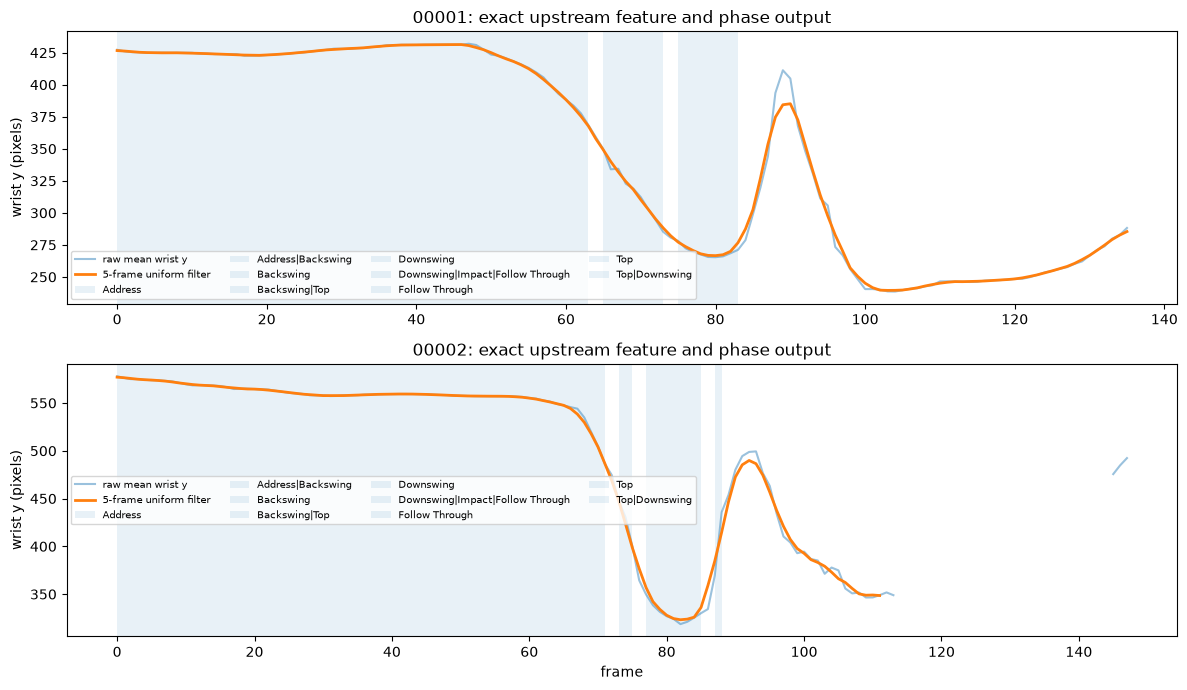

In [2]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=False)
for ax, (name, frame) in zip(axes, traces.items()):
    ax.plot(frame.frame_idx, frame.wrist_y, alpha=.45, label="raw mean wrist y")
    ax.plot(frame.frame_idx, frame.smoothed_wrist_y, lw=2, label="5-frame uniform filter")
    for phase, group in frame[frame.phase.ne("")].groupby("phase"):
        ax.axvspan(group.frame_idx.min(), group.frame_idx.max(), alpha=.10, label=phase)
    ax.set(title=f"{name}: exact upstream feature and phase output", ylabel="wrist y (pixels)")
    ax.legend(ncol=4, fontsize=7)
axes[-1].set_xlabel("frame")
plt.tight_layout()
plt.show()

In [3]:
rows = []
for clip in ("00001", "00002"):
    for phase, midpoint in summary[clip]["normalized_phase_midpoints"].items():
        rows.append((clip, phase, midpoint))
midpoints = pd.DataFrame(rows, columns=["clip", "phase", "normalized_midpoint"])
display(midpoints.pivot(index="phase", columns="clip", values="normalized_midpoint"))

clip,00001,00002
phase,,
Address,-1.391304,-2.000000
Backswing,0.217391,0.111111
Downswing,0.913043,0.861111
Follow Through,0.978261,0.972222
Impact,0.956522,0.944444
Top,0.652174,0.500000


## Algorithm and data audit

- Pose is MediaPipe. The only retained signal is the average visible left/right wrist pixel Y; landmark visibility must exceed 0.4. X, Z, individual wrists, all other joints, detection confidence, frame timestamps, and raw pose results are discarded.
- The signal uses a five-frame uniform filter. Missing wrist samples remain NaN and can contaminate neighbouring filtered values.
- Start is the first wrist-velocity sample over the 90th percentile; end is the closest return after the peak. Address is a backward flat window; top is a wrist-Y minimum around the first slope reversal; impact is the maximum plateau after top. Six contiguous named ranges are then constructed.
- The “pro vs student” comparison selects one middle frame per phase. It does not calculate continuous trajectory distance, uncertainty, consistency, or outcome association.
- This run usefully shows a compact phase-normalization concept, but the phase names have no labelled-event validation and the heuristic is sensitive to crop, handedness, occlusion, FPS, and extra motion.

In [4]:
audit = pd.DataFrame([
    ("pose execution", "observed", "MediaPipe completed both clips"),
    ("raw body trajectory", "not retained", "only mean wrist pixel Y"),
    ("phase ranges", "observed heuristic", "six ranges from wrist Y/velocity"),
    ("club/ball", "absent", "no observation or labels"),
    ("comparison", "qualitative", "middle frame per phase"),
    ("licence", "MIT", "LICENSE present"),
], columns=["capability", "status", "basis"])
display(audit)
print("EXECUTED_OK: GolfPosePro component notebook")

,capability,status,basis
0,pose execution,observed,MediaPipe completed both clips
1,raw body trajectory,not retained,only mean wrist pixel Y
2,phase ranges,observed heuristic,six ranges from wrist Y/velocity
3,club/ball,absent,no observation or labels
4,comparison,qualitative,middle frame per phase
5,licence,MIT,LICENSE present


EXECUTED_OK: GolfPosePro component notebook
